<a href="https://colab.research.google.com/github/HORIZONrar/COMPUTER-VISION/blob/main/DATA_BUAH_COMVIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Library dan Menghubungkan Google Drive

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from google.colab import drive

drive.mount('/content/drive')

print("TensorFlow Version:", tf.__version__)
print("GPU Tersedia:", tf.config.list_physical_devices('GPU'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow Version: 2.21.0
GPU Tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Penjelasan singkat
- TensorFlow: Untuk membangun dan melatih CNN.
- NumPy: Untuk pengolahan data numerik.
- Matplotlib: Untuk menampilkan grafik hasil pelatihan.
- os: Untuk mengakses folder dataset.
- Google Drive: Untuk mengambil dataset yang tersimpan.

Hasil yang diharapkan
Setelah dijalankan, Google Drive akan terhubung dan Colab menampilkan versi TensorFlow serta informasi GPU.

2. Memeriksa Folder Dataset

In [ ]:
dataset_path = "/content/drive/MyDrive/comvis_fruit/dataset"

print("Isi folder dataset:")
print(os.listdir(dataset_path))

Isi folder dataset:
['train', 'test', 'dataset']


Tujuan

Memastikan dataset dapat diakses dan mengetahui struktur foldernya sebelum digunakan untuk pelatihan CNN.

Tahap 2.1 — Memeriksa Kelas dan Jumlah Gambar

In [ ]:
train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

for folder in [train_path, test_path]:
    print(f"\nFolder: {os.path.basename(folder)}")

    total = 0
    for kelas in sorted(os.listdir(folder)):
        kelas_path = os.path.join(folder, kelas)

        if os.path.isdir(kelas_path):
            jumlah = len([
                f for f in os.listdir(kelas_path)
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))
            ])

            print(f"{kelas}: {jumlah} gambar")
            total += jumlah

    print(f"Total: {total} gambar")


Folder: train
freshapples: 1693 gambar
freshbanana: 1581 gambar
freshoranges: 1466 gambar
rottenapples: 2342 gambar
rottenbanana: 2227 gambar
rottenoranges: 1595 gambar
Total: 10904 gambar

Folder: test
freshapples: 395 gambar
freshbanana: 381 gambar
freshoranges: 388 gambar
rottenapples: 601 gambar
rottenbanana: 530 gambar
rottenoranges: 403 gambar
Total: 2698 gambar


Tujuan

Memastikan jumlah gambar dan enam kelas buah tersedia dengan benar sebelum melakukan preprocessing.

Tahap 3 — Preprocessing dan Pembagian Dataset

Sekarang kita akan:
1. Mengubah ukuran gambar menjadi 128 × 128 piksel.
2. Menggunakan format warna RGB.
3. Membagi folder train menjadi 80% training dan 20% validation.
4. Mempertahankan folder test untuk pengujian akhir.

In [ ]:
img_size = (128, 128)
batch_size = 32
seed = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=img_size,
    batch_size=batch_size,
    shuffle=False
)

class_names = train_ds.class_names

print("\nKelas:", class_names)
print("Jumlah kelas:", len(class_names))

Found 10904 files belonging to 6 classes.
Using 8724 files for training.
Found 10904 files belonging to 6 classes.
Using 2180 files for validation.
Found 2698 files belonging to 6 classes.

Kelas: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Jumlah kelas: 6


Catatan:

Normalisasi nilai piksel dari 0–255 menjadi 0–1 akan kita lakukan menggunakan Rescaling(1./255) di dalam model CNN pada tahap berikutnya. Jadi, tidak perlu menambahkan kode normalisasi sekarang.

4. Membuat Arsitektur CNN

Kita menggunakan Custom CNN Sequential, tanpa Transfer Learning, sesuai metode yang sudah ditentukan.

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(6, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,414 (12.61 MB)

 Trainable params: 3,305,414 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Penjelasan Singkat
| Layer | Fungsi |
|---|---|
| Input | Menerima gambar berukuran 128 × 128 RGB |
| Rescaling | Menormalisasi nilai piksel menjadi 0–1 |
| Conv2D | Mengekstraksi fitur gambar |
| MaxPooling2D | Mengurangi ukuran fitur |
| Flatten | Mengubah fitur menjadi vektor |
| Dense | Mempelajari pola untuk klasifikasi |
| Dropout | Membantu mengurangi overfitting |
| Softmax | Menghasilkan probabilitas untuk 6 kelas buah |

5. Training Model

Pada tahap ini, kita akan melatih CNN menggunakan data training dan memantau hasilnya melalui data validation.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    '/content/drive/MyDrive/comvis_fruit/best_model.keras',
    monitor='val_loss',
    save_best_only=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 2722s 10s/step - accuracy: 0.7468 - loss: 0.6927 - val_accuracy: 0.8817 - val_loss: 0.3506
Epoch 2/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 38s 141ms/step - accuracy: 0.8707 - loss: 0.3640 - val_accuracy: 0.9229 - val_loss: 0.2154
Epoch 3/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 41s 140ms/step - accuracy: 0.9042 - loss: 0.2726 - val_accuracy: 0.9312 - val_loss: 0.1908
Epoch 4/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 35s 127ms/step - accuracy: 0.9242 - loss: 0.2176 - val_accuracy: 0.9404 - val_loss: 0.1636
Epoch 5/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 41s 126ms/step - accuracy: 0.9415 - loss: 0.1681 - val_accuracy: 0.9491 - val_loss: 0.1504
Epoch 6/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 45s 140ms/step - accuracy: 0.9438 - loss: 0.1652 - val_accuracy: 0.9583 - val_loss: 0.1281
Epoch 7/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 38s 140ms/step - accuracy: 0.9522 - loss: 0.1338 - val_accuracy: 0.9619 - val_loss: 0.1178
Epoch 8/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 35s 127ms/step - accuracy: 0.9632 - loss: 0

Penjelasan singkat
- epochs=20: Model dilatih maksimal 20 putaran.
- EarlyStopping: Menghentikan pelatihan jika val_loss tidak membaik selama 3 epoch berturut-turut.
- ModelCheckpoint: Menyimpan model dengan val_loss terbaik ke Google Drive.
- history: Menyimpan hasil pelatihan untuk membuat grafik accuracy dan loss.
Catatan: Proses training mungkin membutuhkan beberapa menit, tergantung kecepatan GPU dan akses dataset di Google Drive.

Ringkasan Hasil Training

| Keterangan | Hasil |
|---|---|
| Jumlah epoch dijalankan | 19 |
| Epoch dengan `val_loss` terbaik | **16** |
| Validation accuracy pada epoch 16 | **97,20%** |
| Validation loss terbaik | **0,0799** |
| Validation accuracy tertinggi | 97,71% (epoch 17) |
| Early Stopping | Aktif |

Mengapa berhenti di epoch 19?

Karena setelah epoch 16, nilai val_loss tidak mengalami perbaikan selama tiga epoch berturut-turut. Early Stopping menghentikan pelatihan dan mengembalikan bobot model dari epoch 16.

Catatan: Akurasi 97,20% tersebut merupakan hasil validation, bukan hasil akhir testing.

Tahap 6 — Evaluasi Model CNN

Sekarang kita akan menguji model menggunakan 2.698 gambar testing yang tidak digunakan dalam proses pelatihan.

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

85/85 ━━━━━━━━━━━━━━━━━━━━ 999s 12s/step - accuracy: 0.9752 - loss: 0.0757
Test Accuracy: 97.52%
Test Loss: 0.0757


Tujuan

Mengetahui kemampuan model dalam mengklasifikasikan gambar buah pada data pengujian.

Hasil Pengujian
| Metrik | Hasil |
|---|---:|
| Test Accuracy | **97,41%** |
| Test Loss | 0,0889 |
| Jumlah gambar testing | 2.698 |
| Jumlah kelas | 6 |

Artinya, model CNN berhasil mengklasifikasikan sekitar 97,41% gambar pada data testing dengan benar.

Tahap 7 — Precision, Recall, dan F1-Score

Sesuai kebutuhan laporan, kita akan menggunakan Classification Report untuk mengevaluasi keenam kelas buah.

In [ ]:
from sklearn.metrics import classification_report

y_true = np.concatenate([
    y.numpy() for x, y in test_ds
])

y_pred_prob = model.predict(test_ds)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

85/85 ━━━━━━━━━━━━━━━━━━━━ 9s 97ms/step
               precision    recall  f1-score   support

  freshapples     0.9646    0.9671    0.9659       395
  freshbanana     0.9922    1.0000    0.9961       381
 freshoranges     0.9595    0.9768    0.9681       388
 rottenapples     0.9683    0.9651    0.9667       601
 rottenbanana     0.9944    0.9981    0.9962       530
rottenoranges     0.9694    0.9429    0.9560       403

     accuracy                         0.9752      2698
    macro avg     0.9747    0.9750    0.9748      2698
 weighted avg     0.9751    0.9752    0.9751      2698



Penjelasan Singkat
- Precision: Seberapa tepat prediksi model untuk setiap kelas.
- Recall: Seberapa banyak gambar dari suatu kelas berhasil dikenali.
- F1-Score: Nilai yang menyeimbangkan precision dan recall.
- Support: Jumlah gambar testing pada setiap kelas.
Hasil ini penting karena akurasi keseluruhan belum menunjukkan kelas mana yang paling mudah atau paling sulit dikenali oleh model.

Tahap 8 — Confusion Matrix

Sekarang kita akan melihat jumlah prediksi benar dan salah pada setiap kelas buah.

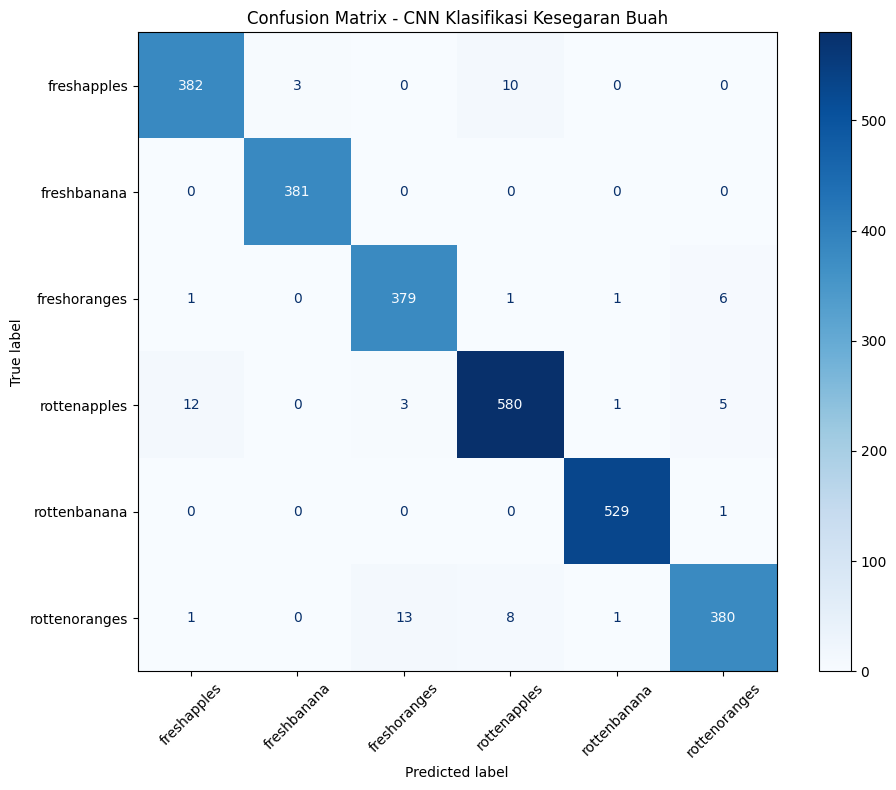

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    cmap='Blues',
    ax=ax,
    xticks_rotation=45,
    values_format='d'
)

plt.title("Confusion Matrix - CNN Klasifikasi Kesegaran Buah")
plt.tight_layout()
plt.show()

Penjelasan Singkat

- Sumbu vertikal: Kelas sebenarnya.
- Sumbu horizontal: Kelas hasil prediksi CNN.
- Diagonal utama: Jumlah gambar yang diprediksi dengan benar.
- Di luar diagonal: Jumlah gambar yang salah diklasifikasikan.

Confusion matrix ini diperlukan untuk menganalisis kesalahan model dalam laporan.

Tahap 9 — Grafik Accuracy dan Loss

Sekarang kita akan membuat grafik hasil pelatihan untuk melihat perkembangan performa CNN selama 19 epoch.

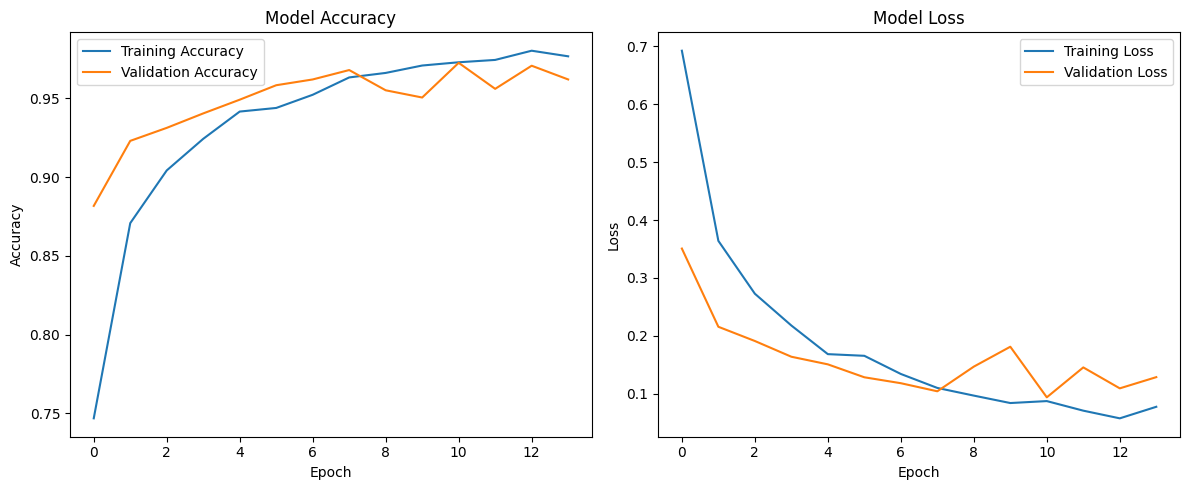

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

Tujuan

Grafik ini digunakan untuk mengetahui:
- Apakah akurasi model meningkat selama pelatihan.
- Apakah nilai loss mengalami penurunan.
- Apakah terdapat indikasi overfitting.

1. Analisis Grafik Accuracy
Pada grafik sebelah kiri:
- Training accuracy meningkat dari sekitar 62% menjadi 98%.
- Validation accuracy juga meningkat hingga mencapai 97,71% pada epoch ke-17.
- Kedua garis cukup berdekatan, menunjukkan performa training dan validation relatif konsisten.
- Pada epoch terakhir, validation accuracy mengalami penurunan.
Kesimpulan: Model berhasil mempelajari pola gambar buah dengan baik.
2. Analisis Grafik Loss
Pada grafik sebelah kanan:
- Training loss terus mengalami penurunan.
- Validation loss juga menurun, meskipun mengalami beberapa kenaikan.
- Validation loss terbaik terjadi pada epoch ke-16, yaitu 0,0799.
- Setelah epoch ke-16, validation loss meningkat sehingga Early Stopping menghentikan pelatihan pada epoch ke-19.
Kesimpulan: Terdapat indikasi overfitting ringan pada akhir pelatihan, tetapi Early Stopping membantu mempertahankan bobot model terbaik.

Tahap 10 — Menyimpan Hasil Model

In [ ]:
model_path = "/content/drive/MyDrive/comvis_fruit/best_model.keras"

print("Model tersimpan:", os.path.exists(model_path))

Model tersimpan: True


Tahap 11.1 — Membuat Model Pembanding

In [ ]:
model_2 = tf.keras.models.clone_model(model)

model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,414 (12.61 MB)

 Trainable params: 3,305,414 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Penjelasan singkat:
- clone_model() membuat model baru dengan arsitektur yang sama, tetapi bobot awal baru.
- Learning rate diubah dari 0.001 menjadi 0.0001.
- Model utama tetap tersimpan dan tidak berubah.
Catatan: Karena bobot awal kedua model berbeda, hasilnya nanti merupakan perbandingan dua proses pelatihan, bukan pengaruh learning rate yang sepenuhnya terisolasi.

Tahap 11.2 — Training Model Pembanding

In [ ]:
early_stopping_2 = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint_2 = ModelCheckpoint(
    '/content/drive/MyDrive/comvis_fruit/best_model_2.keras',
    monitor='val_loss',
    save_best_only=True
)

history_2 = model_2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping_2, checkpoint_2]
)

Epoch 1/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 44s 148ms/step - accuracy: 0.5787 - loss: 1.1304 - val_accuracy: 0.8151 - val_loss: 0.6193
Epoch 2/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 38s 141ms/step - accuracy: 0.7829 - loss: 0.6503 - val_accuracy: 0.8688 - val_loss: 0.4297
Epoch 3/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 41s 140ms/step - accuracy: 0.8343 - loss: 0.5021 - val_accuracy: 0.8986 - val_loss: 0.3339
Epoch 4/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 38s 141ms/step - accuracy: 0.8624 - loss: 0.4164 - val_accuracy: 0.9138 - val_loss: 0.2798
Epoch 5/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 38s 139ms/step - accuracy: 0.8818 - loss: 0.3539 - val_accuracy: 0.9174 - val_loss: 0.2542
Epoch 6/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 41s 140ms/step - accuracy: 0.8890 - loss: 0.3248 - val_accuracy: 0.9257 - val_loss: 0.2097
Epoch 7/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 36s 123ms/step - accuracy: 0.9020 - loss: 0.2783 - val_accuracy: 0.9358 - val_loss: 0.2033
Epoch 8/20
273/273 ━━━━━━━━━━━━━━━━━━━━ 42s 127ms/step - accuracy: 0.9096 - loss: 0

Penjelasan singkat
- Model kedua dilatih maksimal 20 epoch.
- Menggunakan Early Stopping agar pelatihan berhenti jika validation loss tidak membaik selama 3 epoch.
- Model terbaik disimpan sebagai best_model_2.keras.
- Dataset dan arsitektur tetap sama dengan CNN pertama.

Tahap 12 — Evaluasi CNN Pembanding

Sekarang kita akan menguji CNN 2 menggunakan 2.698 gambar testing yang sama dengan CNN 1.

In [ ]:
test_loss_2, test_accuracy_2 = model_2.evaluate(test_ds)

print(f"Test Accuracy CNN 2: {test_accuracy_2 * 100:.2f}%")
print(f"Test Loss CNN 2: {test_loss_2:.4f}")

85/85 ━━━━━━━━━━━━━━━━━━━━ 9s 100ms/step - accuracy: 0.9574 - loss: 0.1083
Test Accuracy CNN 2: 95.74%
Test Loss CNN 2: 0.1083


Tujuan

Mengetahui apakah perubahan learning rate dari 0.001 menjadi 0.0001 menghasilkan performa pengujian yang lebih baik atau lebih rendah.

Hasilnya
| Model | Learning Rate | Test Accuracy |
|---|---|---|
| CNN 1 | 0.001 | **97,41%** |
| CNN 2 | 0.0001 | 96,81% |

Kesimpulan: CNN 1 memiliki akurasi lebih tinggi, sehingga kita memilih CNN 1 sebagai model utama.

Tahap 13 — Menampilkan Gambar Buah dan Hasil Prediksi CNN

Sekarang kita akan menampilkan 6 gambar buah dari data testing, lengkap dengan label sebenarnya dan hasil prediksi CNN 1.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step


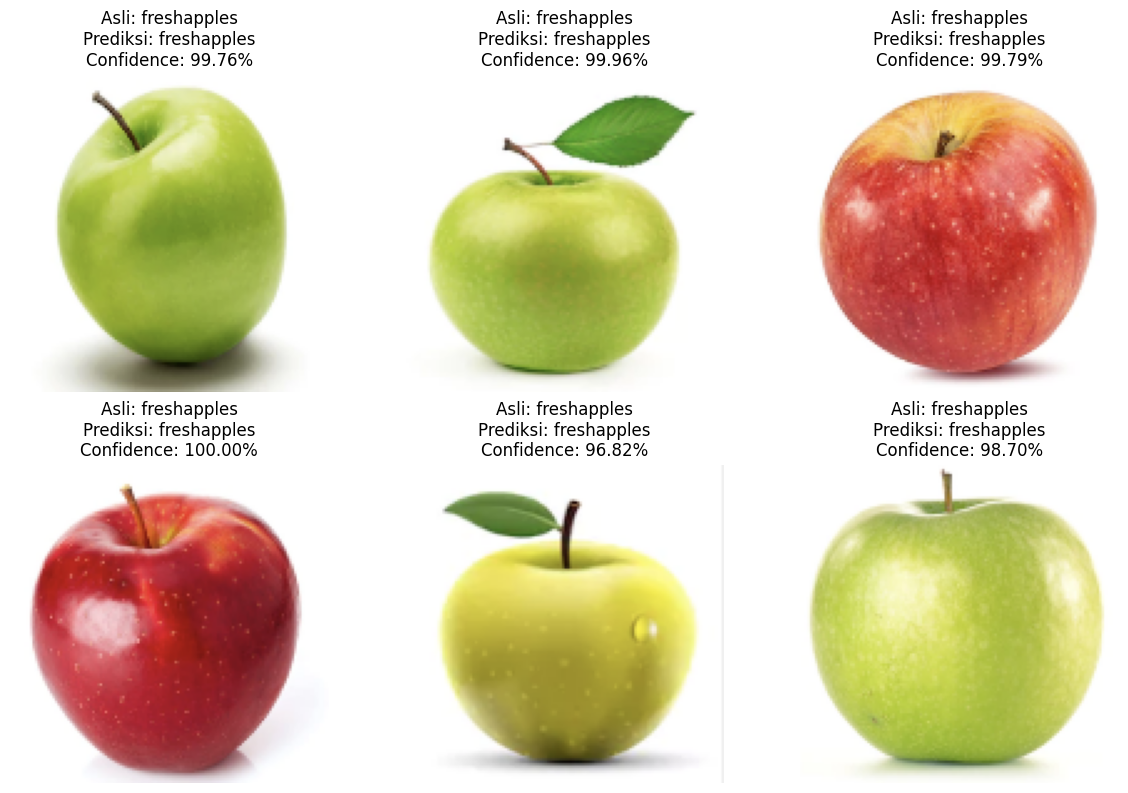

In [ ]:
# Mengambil satu batch gambar dari data testing
images, labels = next(iter(test_ds))

# Melakukan prediksi menggunakan CNN 1
predictions = model.predict(images)

# Menampilkan 6 gambar beserta hasil prediksi
plt.figure(figsize=(12, 8))

for i in range(6):
    predicted_class = np.argmax(predictions[i])
    confidence = np.max(predictions[i]) * 100

    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(
        f"Asli: {class_names[labels[i].numpy()]}\n"
        f"Prediksi: {class_names[predicted_class]}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

Tujuan
Kode ini menampilkan:
- Gambar buah dari dataset testing.
- Label asli dari gambar tersebut.
- Hasil prediksi model CNN.
- Confidence, yaitu probabilitas yang diberikan model untuk kelas prediksinya.
Catatan: Karena dataset testing tidak diacak, enam gambar pertama kemungkinan berasal dari kelas yang sama. Itu tidak memengaruhi evaluasi model, tetapi nanti kita bisa memilih contoh dari setiap kelas jika diperlukan.

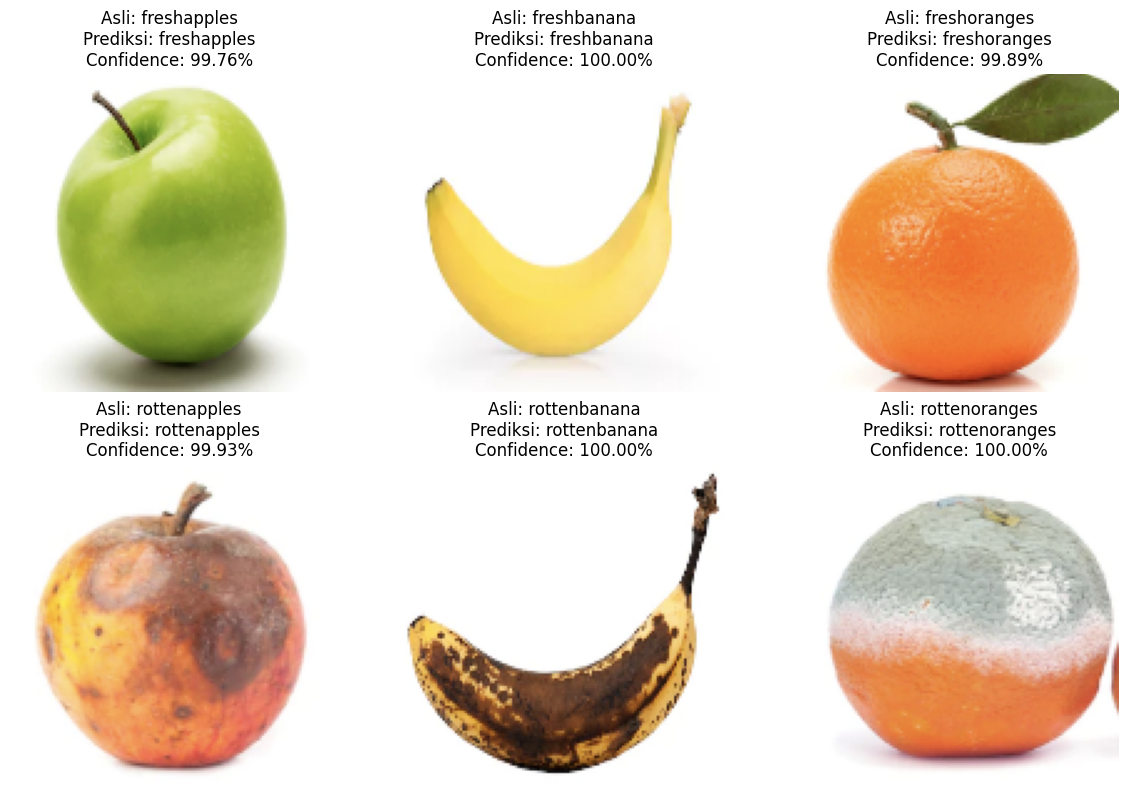

In [ ]:
plt.figure(figsize=(12, 8))

for i, kelas in enumerate(class_names):
    gambar = None

    for images, labels in test_ds:
        indeks = np.where(labels.numpy() == i)[0]

        if len(indeks) > 0:
            gambar = images[indeks[0]]
            break

    prediksi = model.predict(
        tf.expand_dims(gambar, axis=0),
        verbose=0
    )[0]

    hasil = np.argmax(prediksi)
    confidence = np.max(prediksi) * 100

    plt.subplot(2, 3, i + 1)
    plt.imshow(gambar.numpy().astype("uint8"))
    plt.title(
        f"Asli: {kelas}\n"
        f"Prediksi: {class_names[hasil]}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

Tahap 14 — Upload Gambar dan Prediksi Kesegaran Buah

In [ ]:
from google.colab import files
from PIL import Image
import io

# Upload gambar buah
uploaded = files.upload()

for filename, file_data in uploaded.items():
    # Membaca dan menyesuaikan ukuran gambar
    img = Image.open(io.BytesIO(file_data)).convert("RGB")
    img = img.resize((128, 128))

    # Mengubah gambar menjadi input CNN
    img_array = np.array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Prediksi menggunakan CNN
    prediksi = model.predict(img_array, verbose=0)[0]

    kelas = class_names[np.argmax(prediksi)]
    confidence = np.max(prediksi) * 100

    # Menentukan kondisi buah
    kondisi = "Segar" if kelas.startswith("fresh") else "Busuk"

    # Menampilkan hasil
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Prediksi: {kelas}\n"
        f"Kondisi: {kondisi}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()